# MLP : expérimentation sur le dataset de fleurs
Auteure : Nadine Zerguine. Les cas de tests du prof sont dans `[Notebook] MLP - Cas de tests.ipynb`.

Ce notebook entraîne le MLP (Tanh) sur les images de **jasmin**, **jonquille** et **tournesol** et regarde l'effet de ses réglages :
taille de l'image, nombre de neurones cachés, pas d'apprentissage α, nombre d'époques. Puis on garde la meilleure configuration,
on regarde les erreurs par classe et on sauvegarde le modèle pour l'application.

## 1. Mise en place

In [1]:
import os, sys, subprocess
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../python")
import mlp_wrapper as mw
from mlp_wrapper import MLP

LIB = "../python/libmlp.so"
if not os.path.exists(LIB):
    subprocess.run(["g++", "-std=c++20", "-shared", "-fPIC", "-O2", "-o", LIB, "../src/MLP.cpp"], check=True)
mw.load_library(os.path.abspath(LIB))

## 2. Le dataset
Chaque classe a **environ 1456 images d'entraînement et 364 de test** (80 % / 20 %). Les classes jonquille et tournesol ont été complétées
par des copies retournées ou zoomées de leurs propres images (fichiers `*aug_*`), pour avoir autant d'images que jasmin.
Une image est réduite à `t x t` pixels, 3 couleurs, pixels ramenés entre -1 et 1 : `t x t x 3` entrées pour le réseau.

In [2]:
sys.path.insert(0, "../python")
import images_utils as iu

DATASET = "../dataset"
classes = iu.lister_classes_dataset(DATASET)
print("Classes :", classes)


def charger(taille):
    Xtr, ytr, _, _ = iu.charger_dataset(DATASET, "train", classes, taille)
    Xte, yte, chemins, _ = iu.charger_dataset(DATASET, "test", classes, taille)
    return iu.vers_vecteurs(Xtr), ytr, iu.vers_vecteurs(Xte), yte, chemins


X_train, y_train, X_test, y_test, chemins_test = charger(8)
Y_train = iu.etiquettes_pm1(y_train, len(classes))
Y_test = iu.etiquettes_pm1(y_test, len(classes))

print(f"{'classe':12s} {'train':>6s} {'test':>6s}")
for c, nom in enumerate(classes):
    print(f"{nom:12s} {np.sum(y_train == c):6d} {np.sum(y_test == c):6d}")
print(f"entrées par image à 8x8 : {X_train.shape[1]}")

Classes : ['jasmin', 'jonquille', 'sunflower']
classe        train   test
jasmin         1456    364
jonquille      1456    364
sunflower      1456    364
entrées par image à 8x8 : 192


## 3. Expérimentations
Pour chaque réglage on entraîne un réseau `[entrées, H, 3]` et on compare la précision sur le **train** et sur le **test**.
Un grand écart (train haut, test bas) veut dire que le réseau **apprend par cœur** (sur-apprentissage).
Réglage de départ : image 8x8, H = 32 neurones cachés, α = 0.008, 15 époques.

In [3]:
def essayer(X_tr, Y_tr, X_te, Y_te, H, alpha, epochs):
    m = MLP([X_tr.shape[1], H, 3], task="classification", seed=0)
    m.fit(X_tr, Y_tr, alpha=alpha, epochs=epochs, log_every=epochs)
    return m.score(X_tr, Y_tr), m.score(X_te, Y_te)


def tracer(valeurs, resultats, titre, xlabel):
    plt.figure(figsize=(5, 3.6))
    plt.plot([str(v) for v in valeurs], [r[0] for r in resultats], "o-", label="train")
    plt.plot([str(v) for v in valeurs], [r[1] for r in resultats], "o-", label="test")
    plt.title(titre); plt.xlabel(xlabel); plt.ylabel("précision"); plt.grid(alpha=0.3); plt.legend()
    plt.show()

### 3.1 Taille de l'image
Plus l'image est grande, plus il y a d'entrées (donc de poids) à apprendre.

4x4 (48 entrées) : train 85.3% | test 81.2%
8x8 (192 entrées) : train 88.4% | test 80.3%
16x16 (768 entrées) : train 89.7% | test 78.8%


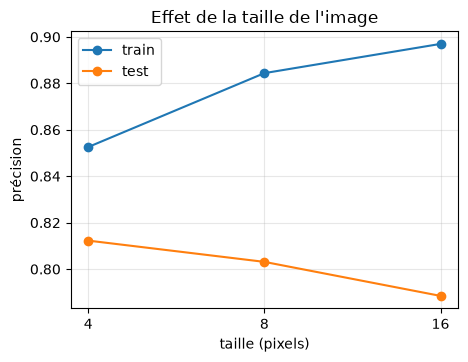

In [4]:
tailles = [4, 8, 16]
resultats = []
for t in tailles:
    Xtr, ytr, Xte, yte, _ = charger(t)
    r = essayer(Xtr, iu.etiquettes_pm1(ytr, 3), Xte, iu.etiquettes_pm1(yte, 3), H=32, alpha=0.008, epochs=15)
    resultats.append(r)
    print(f"{t}x{t} ({Xtr.shape[1]} entrées) : train {r[0]:.1%} | test {r[1]:.1%}")
tracer(tailles, resultats, "Effet de la taille de l'image", "taille (pixels)")

### 3.2 Nombre de neurones cachés H
Plus de neurones = plus de capacité, mais plus de risque d'apprendre par cœur.

H =   4 : train 83.3% | test 79.9%
H =  16 : train 86.0% | test 81.5%
H =  32 : train 88.4% | test 80.3%
H =  64 : train 91.4% | test 81.8%


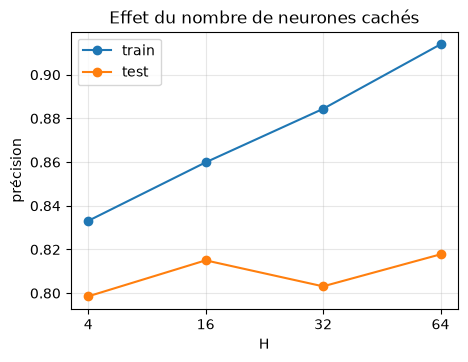

In [5]:
neurones = [4, 16, 32, 64]
resultats = []
for H in neurones:
    r = essayer(X_train, Y_train, X_test, Y_test, H=H, alpha=0.008, epochs=15)
    resultats.append(r)
    print(f"H = {H:3d} : train {r[0]:.1%} | test {r[1]:.1%}")
tracer(neurones, resultats, "Effet du nombre de neurones cachés", "H")

### 3.3 Pas d'apprentissage α
Trop petit : le réseau apprend très lentement. Trop grand : il oscille et n'apprend plus.

α = 0.0005  : train 71.5% | test 70.8%
α = 0.002   : train 81.5% | test 77.0%
α = 0.008   : train 88.4% | test 80.3%
α = 0.03    : train 87.0% | test 81.2%
α = 0.1     : train 75.1% | test 75.0%


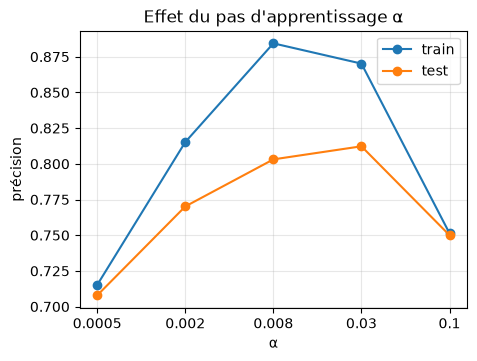

In [6]:
alphas = [0.0005, 0.002, 0.008, 0.03, 0.1]
resultats = []
for a in alphas:
    r = essayer(X_train, Y_train, X_test, Y_test, H=32, alpha=a, epochs=15)
    resultats.append(r)
    print(f"α = {a:<7} : train {r[0]:.1%} | test {r[1]:.1%}")
tracer(alphas, resultats, "Effet du pas d'apprentissage α", "α")

### 3.4 Nombre d'époques
On suit la précision au fil de l'entraînement. Quand la courbe train continue de monter alors que la courbe test se met à plat, le réseau apprend par cœur.

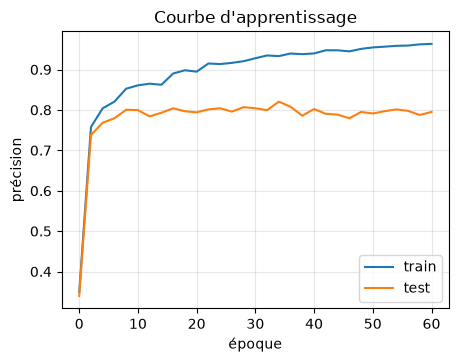

In [7]:
modele = MLP([192, 32, 3], task="classification", seed=0)
historique = modele.fit(X_train, Y_train, alpha=0.008, epochs=60, X_val=X_test, Y_val=Y_test, log_every=2)

plt.figure(figsize=(5, 3.6))
plt.plot(historique["epoch"], historique["train_score"], label="train")
plt.plot(historique["epoch"], historique["val_score"], label="test")
plt.xlabel("époque"); plt.ylabel("précision"); plt.title("Courbe d'apprentissage"); plt.grid(alpha=0.3); plt.legend()
plt.show()

## 4. Modèle retenu
Image 8x8 (192 entrées), H = 32, α = 0.008, 15 époques : MLP `[192, 32, 3]`, soit 6275 poids.

In [8]:
modele = MLP([192, 32, 3], task="classification", seed=0)
modele.fit(X_train, Y_train, alpha=0.008, epochs=15)

print("nombre de poids :", modele.n_weights)
print("précision train :", round(modele.score(X_train, Y_train), 3))
print("précision test  :", round(modele.score(X_test, Y_test), 3))

nombre de poids : 6275
précision train : 0.884
précision test  : 0.803


### Résultat par classe
Ligne = vraie fleur, colonne = fleur prédite. Les bonnes réponses sont sur la diagonale.

In [9]:
predites = np.argmax(modele.predict(X_test), axis=1)
confusion = np.zeros((3, 3), dtype=int)
for vrai, pred in zip(y_test, predites):
    confusion[vrai, pred] += 1

print(f"{'':12s}" + "".join(f"{c:>12s}" for c in classes))
for i, c in enumerate(classes):
    print(f"{c:12s}" + "".join(f"{n:12d}" for n in confusion[i]) + f"   bien classées : {confusion[i, i] / confusion[i].sum():.0%}")

                  jasmin   jonquille   sunflower
jasmin               303          51          10   bien classées : 83%
jonquille             65         266          33   bien classées : 73%
sunflower              6          50         308   bien classées : 85%


### Quelques images mal classées

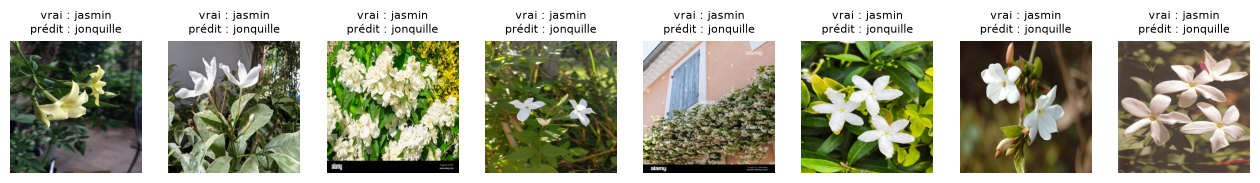

In [10]:
from PIL import Image
mal = np.where(predites != y_test)[0][:8]
plt.figure(figsize=(16, 2.6))
for k, i in enumerate(mal):
    plt.subplot(1, 8, k + 1)
    plt.imshow(Image.open(chemins_test[i]).convert("RGB"))
    plt.title(f"vrai : {classes[y_test[i]]}\nprédit : {classes[predites[i]]}", fontsize=8)
    plt.axis("off")
plt.show()

## 5. Sauvegarder et recharger le modèle
`save` écrit un fichier `.npz` (architecture + poids + noms des classes + taille d'image). `load` recrée le même modèle :
c'est ce fichier que l'application (client / serveur) utilise pour prédire sur de nouvelles images.

In [11]:
os.makedirs("../models/MLP", exist_ok=True)
chemin = modele.save("../models/MLP/mlp_tanh", meta={"classes": classes, "taille_image": 8})
print("modèle écrit dans", chemin)

modele_recharge = MLP.load(chemin)
print("modèle rechargé :", modele_recharge, "| classes :", modele_recharge.meta["classes"])

x = iu.preprocess_image(chemins_test[0], modele_recharge.meta["taille_image"])
sortie = modele_recharge.predict(x)[0]
print("image :", chemins_test[0].split("/")[-1], "| prédite :", classes[int(np.argmax(sortie))], "| vraie :", classes[y_test[0]])
print("mêmes prédictions avant / après sauvegarde :", np.array_equal(modele.predict(X_test), modele_recharge.predict(X_test)))

modèle écrit dans ../models/MLP/mlp_tanh.npz
modèle rechargé : MLP(layers=[192, 32, 3], task='classification') | classes : ['jasmin', 'jonquille', 'sunflower']
image : jasmin_00000.jpg | prédite : jasmin | vraie : jasmin
mêmes prédictions avant / après sauvegarde : True
